**Transformer-only post-processing.** Inherit the same five-layer Transformer and its parameters from cosine_annealing.ipynb, with five disjoint patient folds and seed 42 as post_processing.ipynb. Train for 160 fixed epochs on all fold-training patients, without an internal holdout. Final OFF predictions come directly from the Transformer's regression head. Preprocessing and scalers are fitted on fold-training patients. No final HistGB regressor is fitted.

Run training once to save validation predictions. The smoothing and plotting cells can be rerun without retraining. The final cell trains the Transformer on all training patients and exports test predictions using lambda_for_future. Change `PLOT_FOLD` in the original plot cell to choose a split.

**Lambda selection:** inside each saved validation fold, split its held-out patients into five groups. Choose lambda on four groups and score only the fifth, rotating through all groups. Both calibration and evaluation patients were held out from that fold's base model. Never pool predictions from different outer models for this selection: their training patients overlap. The reported MSE uses these patient-held-out lambda choices. A separate lambda fitted using all cached predictions is intended for future patients; its minimum tuning error is not reported as independent performance. This isolates lambda selection, but does not undo earlier encoder selection on these data. See the [cross-validation guidance](https://scikit-learn.org/stable/modules/cross_validation.html).


In [6]:
import json
import ast
from pathlib import Path

PROJECT_DIR = next(p for p in (Path.cwd(), *Path.cwd().parents)
                   if (p / "exploration/features_selection.ipynb").is_file())
encoder_definitions = json.loads(
    (PROJECT_DIR / "exploration/stacking/cosine_annealing.ipynb").read_text()
)
# Setup and function definitions only: no validation, search or final training.
for i in [2, 4, 6, 8, 10]:
    exec("".join(encoder_definitions["cells"][i]["source"]).replace(
        'print(f"Device: {DEVICE}; baseline: {baseline[-1]}")',
        'print(f"Device: {DEVICE}; final model: Transformer")'))
baseline = baseline[:2]  # Keep only the encoder preprocessing.

FIXED_EPOCHS = 160
# Import only the fixed-epoch helper, without executing its comparison loop.
fixed_source = "".join(next(c for c in encoder_definitions["cells"]
                            if c.get("id") == "cosine-fixed-cv")["source"])
fixed_function = next(f for f in ast.parse(fixed_source).body
                      if isinstance(f, ast.FunctionDef) and f.name == "fit_encoder_full")
exec(ast.get_source_segment(fixed_source, fixed_function))

# Encoder parameters and seed are inherited from cosine_annealing.ipynb.
PREDICTIONS_PATH = PROJECT_DIR / "data/post_processing_transformer_validation_predictions.csv"


Device: mps; final model: Transformer


In [7]:
cv = GroupKFold(n_splits=5, shuffle=True, random_state=SEED)
scores, validation_predictions = [], []
with threadpool_limits(limits=3):
    for fold, (train_idx, val_idx) in enumerate(cv.split(X, y, groups=X["patient_id"]), 1):
        raw_train, raw_val = X.iloc[train_idx], X.iloc[val_idx]
        yt, yv = y.iloc[train_idx], y.iloc[val_idx]
        prep = clone(baseline).fit(raw_train, yt)
        fitted_encoder = fit_encoder_full(raw_train, yt, prep, SEED, FIXED_EPOCHS)
        _, prediction = encoder_outputs(fitted_encoder, raw_val)
        mse = mean_squared_error(yv, prediction)
        scores.append(dict(fold=fold, epochs=fitted_encoder["epochs"], MSE=mse))
        validation_predictions.append(raw_val[["Index", "patient_id", "age"]].assign(
            fold=fold, target=yv, prediction=prediction
        ))
        print(f"Fold {fold}/5: MSE {mse:.4f}, RMSE {np.sqrt(mse):.4f}")

validation_predictions = pd.concat(validation_predictions, ignore_index=True)
validation_predictions.to_csv(PREDICTIONS_PATH, index=False)
scores = pd.DataFrame(scores)
scores["RMSE"] = np.sqrt(scores["MSE"])
print(f"CV MSE: {scores.MSE.mean():.4f} ± {scores.MSE.std(ddof=0):.4f}; "
      f"RMSE: {np.sqrt(scores.MSE.mean()):.4f}")
scores


Fold 1/5: MSE 6.4651, RMSE 2.5427
Fold 2/5: MSE 6.6750, RMSE 2.5836
Fold 3/5: MSE 6.6309, RMSE 2.5751
Fold 4/5: MSE 7.1065, RMSE 2.6658
Fold 5/5: MSE 6.3877, RMSE 2.5274
CV MSE: 6.6530 ± 0.2499; RMSE: 2.5793


,fold,epochs,MSE,RMSE
0,1,160,6.465105,2.542657
1,2,160,6.674968,2.583596
2,3,160,6.630901,2.575054
3,4,160,7.106476,2.665798
4,5,160,6.387748,2.527399


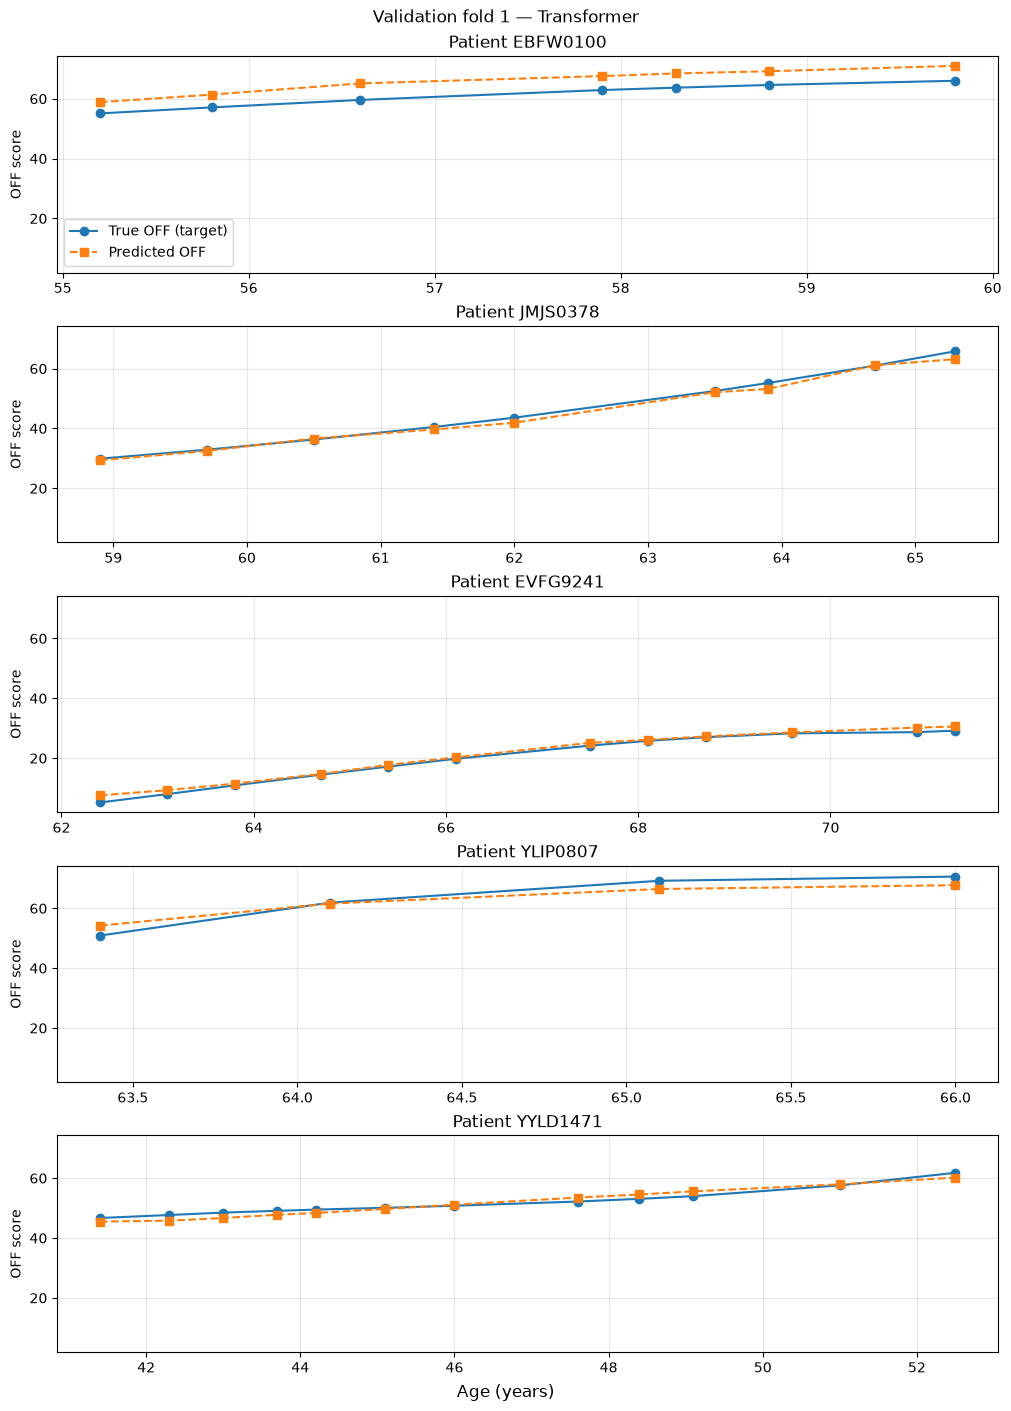

In [8]:
# This cell also runs on its own after a kernel restart, once the CSV exists.
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

plot_root = next(p for p in (Path.cwd(), *Path.cwd().parents)
                 if (p / "exploration/features_selection.ipynb").is_file())
plot_data = pd.read_csv(plot_root / "data/post_processing_transformer_validation_predictions.csv")
PLOT_FOLD = 1
plot_data = plot_data.loc[plot_data["fold"].eq(PLOT_FOLD)]
patients = plot_data["patient_id"].drop_duplicates().sample(5, random_state=42)

fig, axes = plt.subplots(5, 1, figsize=(10, 14), sharey=True, layout="constrained")
for ax, patient in zip(axes, patients):
    visits = plot_data.loc[plot_data["patient_id"].eq(patient)].sort_values("age")
    ax.plot(visits["age"], visits["target"], "o-", label="True OFF (target)")
    ax.plot(visits["age"], visits["prediction"], "s--", label="Predicted OFF")
    ax.set(title=f"Patient {patient}", ylabel="OFF score")
    ax.grid(alpha=0.3)
axes[0].legend()
fig.suptitle(f"Validation fold {PLOT_FOLD} — Transformer")
fig.supxlabel("Age (years)")
plt.show()


In [9]:
import numpy as np
from scipy.optimize import minimize, LinearConstraint
from sklearn.isotonic import isotonic_regression
from sklearn.model_selection import GroupKFold

LAMBDA_GRID = np.r_[0.0, np.logspace(-1, 3, 9)]
def smooth_patient(g, strength):
    p, t = g["prediction"].to_numpy(), g["age"].to_numpy()
    if strength == 0:
        return isotonic_regression(p, increasing=True)
    center = p.mean()
    p = p - center
    t = (t - t[0]) / (t[-1] - t[0])
    A = np.diff(np.eye(len(p)), axis=0)
    D = np.diff(A / np.diff(t)[:, None], axis=0)
    D /= np.linalg.norm(D)
    H = np.eye(len(p)) + strength * D.T @ D
    result = minimize(
        lambda z: ((z - p)**2).sum() + strength * ((D @ z)**2).sum(),
        np.maximum.accumulate(np.linalg.solve(H, p)), jac=lambda z: 2 * (H @ z - p),
        constraints=LinearConstraint(A, 0, np.inf), method="SLSQP",
        options={"ftol": 1e-9, "maxiter": 300},
    )
    if not result.success:
        raise RuntimeError(result.message)
    return result.x + center

smooth = pd.read_csv(plot_root / "data/post_processing_transformer_validation_predictions.csv")
smooth = smooth.sort_values(["fold", "patient_id", "age"])
candidates = pd.DataFrame(index=smooth.index, columns=LAMBDA_GRID, dtype=float)
for strength in LAMBDA_GRID:
    for _, g in smooth.groupby(["fold", "patient_id"], sort=False):
        candidates.loc[g.index, strength] = smooth_patient(g, strength)
    print(f"Computed predictions for lambda={strength:g}", flush=True)
errors = candidates.sub(smooth["target"], axis=0).pow(2)

# Tune only on OTHER patients held out from the SAME base model.
smooth["smoothed"] = np.nan
choices = []
for fold, g in smooth.groupby("fold", sort=False):
    calibration_cv = GroupKFold(n_splits=5, shuffle=True, random_state=42)
    for group, (cal_idx, eval_idx) in enumerate(
        calibration_cv.split(g, groups=g["patient_id"]), 1
    ):
        cal_rows, eval_rows = g.index[cal_idx], g.index[eval_idx]
        strength = errors.loc[cal_rows].mean().idxmin()
        smooth.loc[eval_rows, "smoothed"] = candidates.loc[eval_rows, strength]
        smooth.loc[eval_rows, "lambda"] = strength
        choices.append(dict(fold=fold, group=group, strength=strength))

mse = smooth.assign(before=(smooth.prediction - smooth.target)**2,
                    after=(smooth.smoothed - smooth.target)**2).groupby("fold")[["before", "after"]].mean()
print(f"Patient-held-out CV MSE: {mse.before.mean():.6f} → {mse.after.mean():.6f}")
lambda_choices = pd.DataFrame(choices)
print(lambda_choices.pivot(index="fold", columns="group", values="strength"))
# Refit lambda on all cached predictions for FUTURE patients, not to report its minimum MSE.
lambda_for_future = errors.groupby(smooth["fold"]).mean().mean().idxmin()
print(f"Lambda for future predictions: {lambda_for_future:g}")
smooth.to_csv(plot_root / "data/post_processing_transformer_tuned_predictions.csv", index=False)


Computed predictions for lambda=0
Computed predictions for lambda=0.1
Computed predictions for lambda=0.316228
Computed predictions for lambda=1
Computed predictions for lambda=3.16228
Computed predictions for lambda=10
Computed predictions for lambda=31.6228
Computed predictions for lambda=100
Computed predictions for lambda=316.228
Computed predictions for lambda=1000
Patient-held-out CV MSE: 6.653040 → 6.633634
group         1         2         3         4         5
fold                                                   
1      1.000000  1.000000  1.000000  1.000000  1.000000
2      1.000000  1.000000  3.162278  3.162278  3.162278
3      3.162278  3.162278  3.162278  1.000000  3.162278
4      1.000000  1.000000  1.000000  1.000000  1.000000
5      1.000000  1.000000  1.000000  1.000000  1.000000
Lambda for future predictions: 1


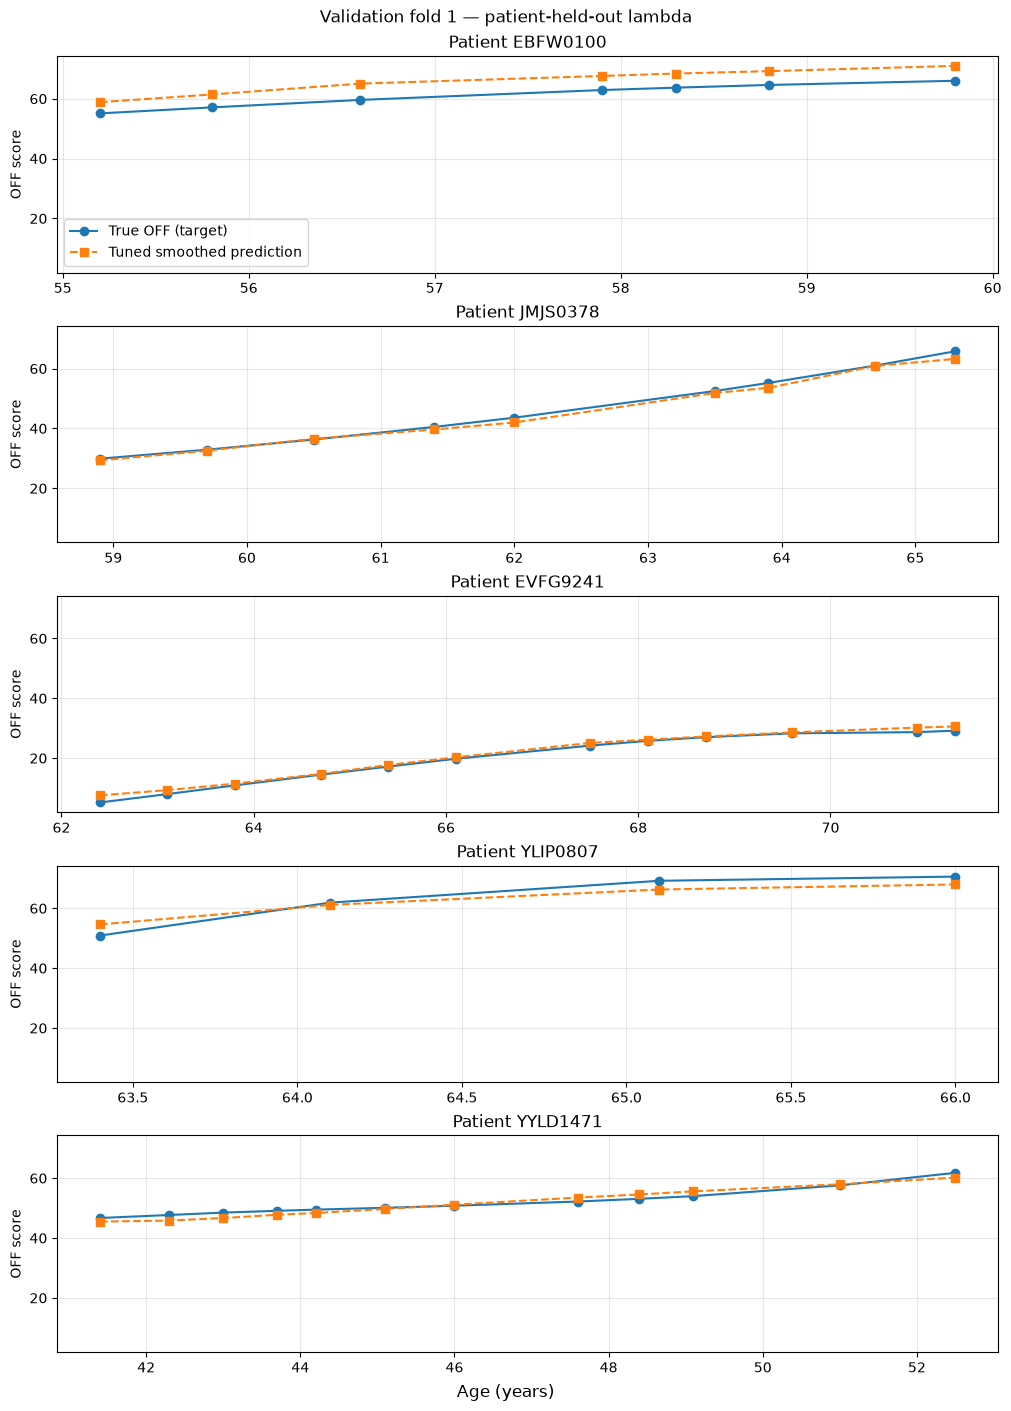

In [10]:
# Replot cached, patient-held-out results without rerunning the lambda search.
tuned_plot = pd.read_csv(plot_root / "data/post_processing_transformer_tuned_predictions.csv")
fig, axes = plt.subplots(5, 1, figsize=(10, 14), sharey=True, layout="constrained")
for ax, patient in zip(axes, patients):
    visits = tuned_plot.loc[tuned_plot["fold"].eq(PLOT_FOLD) & tuned_plot["patient_id"].eq(patient)]
    ax.plot(visits["age"], visits["target"], "o-", label="True OFF (target)")
    ax.plot(visits["age"], visits["smoothed"], "s--", label="Tuned smoothed prediction")
    ax.set(title=f"Patient {patient}", ylabel="OFF score")
    ax.grid(alpha=0.3)
axes[0].legend()
fig.suptitle(f"Validation fold {PLOT_FOLD} — patient-held-out lambda")
fig.supxlabel("Age (years)")
plt.show()


In [11]:
# Final fit on all training patients, then test prediction and smoothing.
RUN_FINAL = True
FINAL_SEED = 42

if RUN_FINAL:
    FINAL_LAMBDA = lambda_for_future
    X_test = pd.read_csv(DATA_DIR / "X_test_oiZ2ukx.csv")[X.columns]
    with threadpool_limits(limits=3):
        final_prep = clone(baseline).fit(X, y)
        final_encoder = fit_encoder_full(X, y, final_prep, FINAL_SEED, FIXED_EPOCHS)
        _, prediction = encoder_outputs(final_encoder, X_test)
    final_prediction = prediction.copy()
    for _, g in X_test.assign(prediction=prediction).sort_values(["patient_id", "age"]).groupby("patient_id"):
        final_prediction.loc[g.index] = smooth_patient(g, FINAL_LAMBDA)
    assert np.isfinite(final_prediction).all()
    submission = pd.DataFrame({"Index": X_test["Index"], "target": final_prediction})
    assert submission["Index"].equals(X_test["Index"])
    submission_path = DATA_DIR / "submission_transformer_post_processed.csv"
    submission.to_csv(submission_path, index=False)
    print(f"Saved {submission_path} ({len(submission):,} visits, lambda={FINAL_LAMBDA:g})")


Saved /Users/Luc/Library/CloudStorage/OneDrive-Personal/Documents/Cours/MS2A/Apprentissage Statistique/Méthodologie/Challenge_Parkinson_disease/data/submission_transformer_post_processed.csv (23,672 visits, lambda=1)
